# **TikTok Project**
**Course 5 - The Nuts and bolts of machine learning**

Recall that you are a data professional at TikTok. Your supervisor was impressed with the work you have done and has requested that you **build a machine learning model that can be used to determine whether a video contains a claim or whether it offers an opinion**. With a successful prediction model, TikTok can reduce the backlog of user reports and prioritize them more efficiently.

A notebook was structured and prepared to help you in this project. Please complete the following questions.

# **Course 5 End-of-course project: Classifying videos using machine learning**

In this activity, you will practice using machine learning techniques to predict on a binary outcome variable.
<br/>

**The purpose** of this model is to increase response time and system efficiency by automating the initial stages of the claims process.

**The goal** of this model is to predict whether a TikTok video presents a "claim" or presents an "opinion".
<br/>

*This activity has three parts:*

**Part 1:** Ethical considerations
* Consider the ethical implications of the request

* Should the objective of the model be adjusted?

**Part 2:** Feature engineering

* Perform feature selection, extraction, and transformation to prepare the data for modeling

**Part 3:** Modeling

* Build the models, evaluate them, and advise on next steps

Follow the instructions and answer the questions below to complete the activity. Then, you will complete an Executive Summary using the questions listed on the PACE Strategy Document.

Be sure to complete this activity before moving on. The next course item will provide you with a completed exemplar to compare to your own work.



# **Classify videos using machine learning**

<img src="images/Pace.png" width="100" height="100" align=left>

# **PACE stages**


Throughout these project notebooks, you'll see references to the problem-solving framework PACE. The following notebook components are labeled with the respective PACE stage: Plan, Analyze, Construct, and Execute.

<img src="images/Plan.png" width="100" height="100" align=left>


## **PACE: Plan**

Consider the questions in your PACE Strategy Document to reflect on the Plan stage.

In this stage, consider the following questions:


1.   **What are you being asked to do? What metric should I use to evaluate success of my business/organizational objective?**

2.   **What are the ethical implications of the model? What are the consequences of your model making errors?**
  *   What is the likely effect of the model when it predicts a false negative (i.e., when the model says a video does not contain a claim and it actually does)?

  *   What is the likely effect of the model when it predicts a false positive (i.e., when the model says a video does contain a claim and it actually does not)?

3.   **How would you proceed?**


1. Response
**Objetivo:** Construir e avaliar um modelo de floresta aleatória capaz de classificar vídeos como reivindicações (claims) ou opiniões (opinions), auxiliando o processo de moderação e priorização de conteúdo no TikTok.

**Métrica:** O recall deve ser uma métrica prioritária, pois é importante identificar o maior número possível de vídeos que realmente contêm reivindicações. Deixar passar uma reivindicação potencialmente problemática pode ter consequências mais graves do que sinalizar um vídeo para revisão adicional.

2. Response

O modelo pode influenciar decisões de moderação de conteúdo e, portanto, possui implicações éticas importantes. Erros de classificação podem afetar usuários, criadores de conteúdo e a confiança na plataforma. 
- Um falso negativo ocorre quando o modelo identifica um vídeo como opinião quando ele realmente contém uma reivindicação, permitindo que conteúdo potencialmente enganoso permaneça sem revisão. 
- Um falso positivo ocorre quando o modelo identifica um vídeo como reivindicação quando ele é apenas uma opinião, gerando revisões desnecessárias e aumentando a carga de trabalho da equipe de moderação.

3. Response

Eu prosseguiria treinando e avaliando o modelo de floresta aleatória utilizando os dados disponíveis e comparando seu desempenho por meio de métricas como recall, precisão e F1-score. Após validar seu desempenho, utilizaria o modelo como uma ferramenta de triagem para identificar vídeos que merecem revisão adicional. Também recomendaria manter supervisão humana para casos mais sensíveis e monitorar continuamente o modelo para garantir precisão e conformidade com os objetivos da plataforma

**Modeling workflow and model selection process**

Previous work with this data has revealed that there are ~20,000 videos in the sample. This is sufficient to conduct a rigorous model validation workflow, broken into the following steps:

1. Split the data into train/validation/test sets (60/20/20)
2. Fit models and tune hyperparameters on the training set
3. Perform final model selection on the validation set
4. Assess the champion model's performance on the test set

![](https://raw.githubusercontent.com/adacert/tiktok/main/optimal_model_flow_numbered.svg)


### **Task 1. Imports and data loading**

Start by importing packages needed to build machine learning models to achieve the goal of this project.

In [1]:
# Import packages for data manipulation
import pandas as pd
import numpy as np

# Import packages for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import packages for data preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Import packages for data modeling
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from xgboost import plot_importance

Now load the data from the provided csv file into a dataframe.

**Note:** As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [2]:
# Load dataset into dataframe
data = pd.read_csv("tiktok_dataset.csv")

<img src="images/Analyze.png" width="100" height="100" align=left>

## **PACE: Analyze**

Consider the questions in your PACE Strategy Document to reflect on the Analyze stage.

### **Task 2: Examine data, summary info, and descriptive stats**

Inspect the first five rows of the dataframe.

In [3]:
# Display first few rows
data.head()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


Get the number of rows and columns in the dataset.

In [4]:
# Get number of rows and columns
data.shape


(19382, 12)

Get the data types of the columns.

In [5]:
# Get data types of columns
data.dtypes


#                             int64
claim_status                 object
video_id                      int64
video_duration_sec            int64
video_transcription_text     object
verified_status              object
author_ban_status            object
video_view_count            float64
video_like_count            float64
video_share_count           float64
video_download_count        float64
video_comment_count         float64
dtype: object

Get basic information about the dataset.

In [6]:
# Get basic information
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  object 
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  object 
 5   verified_status           19382 non-null  object 
 6   author_ban_status         19382 non-null  object 
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), object(4)
memory usage: 1.8+ MB


Generate basic descriptive statistics about the dataset.

In [7]:
# Generate basic descriptive stats
data.describe()

,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,1.938200e+04,19382.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9691.500000,5.627454e+09,32.421732,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,2.536440e+09,16.229967,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,3.430417e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,5.618664e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,7.843960e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19382.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


Check for and handle missing values.

In [8]:
# Check for missing values
data.isna().sum()


#                             0
claim_status                298
video_id                      0
video_duration_sec            0
video_transcription_text    298
verified_status               0
author_ban_status             0
video_view_count            298
video_like_count            298
video_share_count           298
video_download_count        298
video_comment_count         298
dtype: int64

In [9]:
# Drop rows with missing values
data = data.dropna(axis=0)


In [10]:

# Display first few rows after handling missing values
data.head()


,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


Check for and handle duplicates.

In [11]:
# Check for duplicates
data.duplicated(subset=None).sum()


0

Check for and handle outliers.

**Response:** Modelos baseados em árvores são robustos a outliers; portanto, não há necessidade de imputar, remover ou modificar valores

Check class balance.

In [12]:
# Check class balance
data['claim_status'].value_counts(normalize=True)


claim_status
claim      0.503458
opinion    0.496542
Name: proportion, dtype: float64

**Response:** A variável-alvo claim_status está bem balanceada, com aproximadamente 50,3% de vídeos classificados como "claim" e 49,7% como "opinion". Portanto, não é necessário aplicar técnicas de balanceamento antes do treinamento do modelo.

<img src="images/Construct.png" width="100" height="100" align=left>

## **PACE: Construct**
Consider the questions in your PACE Strategy Document to reflect on the Construct stage.

### **Task 3: Feature engineering**

Extract the length of each `video_transcription_text` and add this as a column to the dataframe, so that it can be used as a potential feature in the model.

In [13]:
# Extract the length of each `video_transcription_text` and add this as a column to the dataframe
data['text_length'] = data['video_transcription_text'].str.len()
data.head()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,text_length
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0,97
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0,107
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0,137
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0,131
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0,128


Calculate the average text_length for claims and opinions.

In [14]:
# Calculate the average text_length for claims and opinions
data.groupby('claim_status')['text_length'].mean()

claim_status
claim      95.376978
opinion    82.722562
Name: text_length, dtype: float64

Visualize the distribution of `text_length` for claims and opinions.

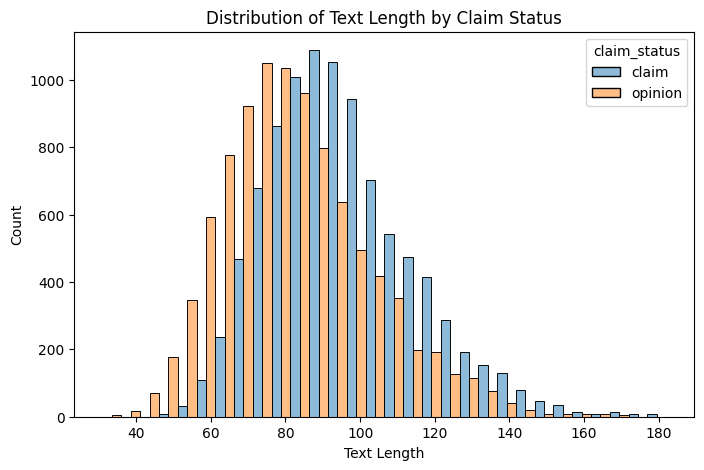

In [15]:
# Visualize the distribution of `text_length` for claims and opinions
# Create two histograms in one plot

plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x='text_length',
    hue='claim_status',
    multiple='dodge',
    bins=30,
    alpha=0.5
)

plt.title('Distribution of Text Length by Claim Status')
plt.xlabel('Text Length')
plt.ylabel('Count')

plt.show()


**Feature selection and transformation**

Encode target and catgorical variables.

In [16]:
# Create a copy of the X data
X = data.copy()

# Drop unnecessary columns
X = X.drop(['#', 'video_id'], axis=1)

# Encode target variable
X['claim_status'] = X['claim_status'].map({'opinion': 0, 'claim': 1})

# Dummy encode remaining categorical values
X = pd.get_dummies(X,
                   columns=['verified_status', 'author_ban_status'],
                   drop_first=True)
X.head()


,claim_status,video_duration_sec,video_transcription_text,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,text_length,verified_status_verified,author_ban_status_banned,author_ban_status_under review
0,1,59,someone shared with me that drone deliveries a...,343296.0,19425.0,241.0,1.0,0.0,97,False,False,True
1,1,32,someone shared with me that there are more mic...,140877.0,77355.0,19034.0,1161.0,684.0,107,False,False,False
2,1,31,someone shared with me that american industria...,902185.0,97690.0,2858.0,833.0,329.0,137,False,False,False
3,1,25,someone shared with me that the metro of st. p...,437506.0,239954.0,34812.0,1234.0,584.0,131,False,False,False
4,1,19,someone shared with me that the number of busi...,56167.0,34987.0,4110.0,547.0,152.0,128,False,False,False


### **Task 4: Split the data**

Assign target variable.

In [17]:
# Isolate target variable
y = X['claim_status']


Isolate the features.

In [18]:
# Isolate features
X = X.drop(['claim_status'], axis=1)

# Display first few rows of features dataframe
X.head()

,video_duration_sec,video_transcription_text,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,text_length,verified_status_verified,author_ban_status_banned,author_ban_status_under review
0,59,someone shared with me that drone deliveries a...,343296.0,19425.0,241.0,1.0,0.0,97,False,False,True
1,32,someone shared with me that there are more mic...,140877.0,77355.0,19034.0,1161.0,684.0,107,False,False,False
2,31,someone shared with me that american industria...,902185.0,97690.0,2858.0,833.0,329.0,137,False,False,False
3,25,someone shared with me that the metro of st. p...,437506.0,239954.0,34812.0,1234.0,584.0,131,False,False,False
4,19,someone shared with me that the number of busi...,56167.0,34987.0,4110.0,547.0,152.0,128,False,False,False


#### **Task 5: Create train/validate/test sets**

Split data into training and testing sets, 80/20.

In [19]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)


Split the training set into training and validation sets, 75/25, to result in a final ratio of 60/20/20 for train/validate/test sets.

In [20]:
# Split the training data into training and validation sets
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=0)


Confirm that the dimensions of the training, validation, and testing sets are in alignment.

In [21]:
# Get shape of each training, validation, and testing set
X_tr.shape, X_val.shape, X_test.shape, y_tr.shape, y_val.shape, y_test.shape

((11450, 11), (3817, 11), (3817, 11), (11450,), (3817,), (3817,))

In [22]:
X_tr_final = pd.concat([X_tr.drop(columns=['video_transcription_text']).reset_index(drop=True)], axis=1)

# Display first few rows
X_tr_final.head()

,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,text_length,verified_status_verified,author_ban_status_banned,author_ban_status_under review
0,51,2487.0,310.0,20.0,1.0,0.0,134,False,False,False
1,43,118512.0,3543.0,374.0,70.0,29.0,97,False,True,False
2,22,105902.0,1885.0,229.0,39.0,9.0,76,False,False,True
3,17,9245.0,1670.0,440.0,13.0,4.0,58,False,False,False
4,18,3791.0,660.0,63.0,9.0,1.0,57,False,False,False


In [23]:
X_val_final = pd.concat([X_val.drop(columns=['video_transcription_text']).reset_index(drop=True)], axis=1)

# Display first few rows
X_val_final.head()

,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,text_length,verified_status_verified,author_ban_status_banned,author_ban_status_under review
0,11,578891.0,379596.0,14612.0,6591.0,44.0,72,False,False,True
1,24,6255.0,1709.0,311.0,13.0,1.0,96,False,False,False
2,35,410356.0,249714.0,26235.0,2060.0,1252.0,88,False,False,False
3,58,406911.0,25986.0,1230.0,564.0,248.0,83,False,False,False
4,47,972573.0,138167.0,25320.0,3331.0,968.0,104,False,False,True


In [24]:
X_test_final = pd.concat([X_test.drop(columns=['video_transcription_text']
                                      ).reset_index(drop=True)], axis=1)
X_test_final.head()

,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,text_length,verified_status_verified,author_ban_status_banned,author_ban_status_under review
0,54,692084.0,135956.0,16591.0,622.0,312.0,107,False,False,False
1,37,5164.0,1858.0,36.0,17.0,1.0,69,True,False,True
2,39,801951.0,344163.0,57608.0,8578.0,2942.0,90,False,False,False
3,44,6429.0,2314.0,847.0,17.0,5.0,76,False,False,False
4,26,555780.0,106863.0,15348.0,252.0,91.0,72,False,False,False


### **Task 6. Build models**


### **Build a random forest model**

Fit a random forest model to the training set. Use cross-validation to tune the hyperparameters and select the model that performs best on recall.

In [25]:
# Instantiate the random forest classifier
rf = RandomForestClassifier(random_state=0)

# Create a dictionary of hyperparameters to tune
cv_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [2, 4, 6],
    'max_features': [0.5, 0.7],
    'max_samples': [0.7, 0.8],
    'min_samples_leaf': [1],
    'min_samples_split': [2]
}


# Define a list of scoring metrics to capture
scoring = ['accuracy', 'precision', 'recall', 'f1']


# Instantiate the GridSearchCV object
rf_cv = GridSearchCV(
    estimator=rf,
    param_grid=cv_params,
    scoring=scoring,
    cv=5,
    refit='recall',
    n_jobs=-1,
    error_score='raise',
    verbose=2
)



In [26]:
### Fit the model to the data 
rf_cv.fit(X_tr_final, y_tr)


Fitting 5 folds for each of 36 candidates, totalling 180 fits
[CV] END max_depth=2, max_features=0.5, max_samples=0.7, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.6s
[CV] END max_depth=2, max_features=0.5, max_samples=0.7, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.6s
[CV] END max_depth=2, max_features=0.5, max_samples=0.7, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.6s
[CV] END max_depth=2, max_features=0.5, max_samples=0.7, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   1.1s
[CV] END max_depth=2, max_features=0.5, max_samples=0.7, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   1.1s
[CV] END max_depth=2, max_features=0.5, max_samples=0.7, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time=   1.6s
[CV] END max_depth=2, max_features=0.5, max_samples=0.7, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time= 

GridSearchCV(cv=5, error_score='raise',
             estimator=RandomForestClassifier(random_state=0), n_jobs=-1,
             param_grid={'max_depth': [2, 4, 6], 'max_features': [0.5, 0.7],
                         'max_samples': [0.7, 0.8], 'min_samples_leaf': [1],
                         'min_samples_split': [2],
                         'n_estimators': [100, 200, 300]},
             refit='recall', scoring=['accuracy', 'precision', 'recall', 'f1'],
             verbose=2)

In [27]:
# Examine best recall score
print(rf_cv.best_score_)
# 0.991026002107111

0.991026002107111


In [28]:
# Examine best parameters
print(rf_cv.best_params_)


{'max_depth': 6, 'max_features': 0.7, 'max_samples': 0.8, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


Check the precision score to make sure the model isn't labeling everything as claims. You can do this by using the `cv_results_` attribute of the fit `GridSearchCV` object, which returns a numpy array that can be converted to a pandas dataframe. Then, examine the `mean_test_precision` column of this dataframe at the index containing the results from the best model. This index can be accessed by using the `best_index_` attribute of the fit `GridSearchCV` object.

In [29]:
# Access the GridSearch results and convert it to a pandas df
results_rf_df = pd.DataFrame(rf_cv.cv_results_)

# Examine the GridSearch results df at column `mean_test_precision` in the best index
results_rf_df.loc[rf_cv.best_index_, 'mean_test_precision']


0.9994785483051682

**Question:** How well is your model performing? Consider average recall score and precision score.

**Response:** O modelo apresentou excelente desempenho, com recall médio de aproximadamente 99,1% e alta precisão. Isso indica que ele identifica corretamente quase todos os casos positivos e produz poucas previsões incorretas

### **Build an XGBoost model**

In [30]:
# Instantiate the XGBoost classifier
xgb = XGBClassifier(objective='binary:logistic', random_state=42)

# Create a dictionary of hyperparameters to tune
cv_params = {
    'max_depth': [4, 6, 12],
    'min_child_weight': [2, 5],
    'learning_rate': [0.01, 0.1],
    'n_estimators': [200, 500]
}

# Define a list of scoring metrics to capture
scoring = ['accuracy', 'precision', 'recall', 'f1']

# Instantiate the GridSearchCV object
xgb_cv = GridSearchCV(xgb, cv_params, scoring=scoring, cv=5, refit='recall')


In [31]:
# Fit the model to the data
xgb_cv.fit(X_tr_final, y_tr)


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None,...
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None,
                                     random_state=42, ...),
             param_grid={'learning_rate': [0.01, 0.1], 'max_depth': [4, 6, 12],
                         'min_child_weight': [2, 5],
                         'n_estimators': [200, 500]},
             refit='recall', scoring=['accuracy', 'precision', 'recall', 'f1'])

In [32]:
# Examine best recall score
print(xgb_cv.best_score_)


0.9898176171763818


In [33]:
# Examine best parameters
print(xgb_cv.best_params_)


{'learning_rate': 0.1, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 200}


Repeat the steps used for random forest to examine the precision score of the best model identified in the grid search.

In [34]:
# Access the GridSearch results and convert it to a pandas df
results_xgb_df = pd.DataFrame(xgb_cv.cv_results_)

# Examine the GridSearch results df at column `mean_test_precision` in the best index

results_xgb_df.loc[xgb_cv.best_index_, 'mean_test_precision']

0.9994762817983982

**Question:** How well does your model perform? Consider recall score and precision score.

**Response:** XGB também apresenta um desempenho muito bom, com métricas de recall e precision muito boas, mas ele se saiu ligeiramente menos eficaz que o random forest, com uma diferença miníma. 

<img src="images/Execute.png" width="100" height="100" align=left>

## **PACE: Execute**
Consider the questions in your PACE Strategy Document to reflect on the Execute stage.

### **Task 7. Evaluate model**

Evaluate models against validation criteria.

#### **Random forest**

In [35]:
# Use the random forest "best estimator" model to get predictions on the validation set
y_preds = rf_cv.best_estimator_.predict(X_val_final)

Display the predictions on the validation set.

In [36]:
# Display the predictions on the validation set
y_preds

array([1, 0, 1, ..., 1, 1, 1])

Display the true labels of the validation set.

In [37]:
# Display the true labels of the validation set
y_val

5846     1
12058    0
2975     1
8432     1
6863     1
        ..
6036     1
6544     1
2781     1
6426     1
4450     1
Name: claim_status, Length: 3817, dtype: int64

Create a confusion matrix to visualize the results of the classification model.

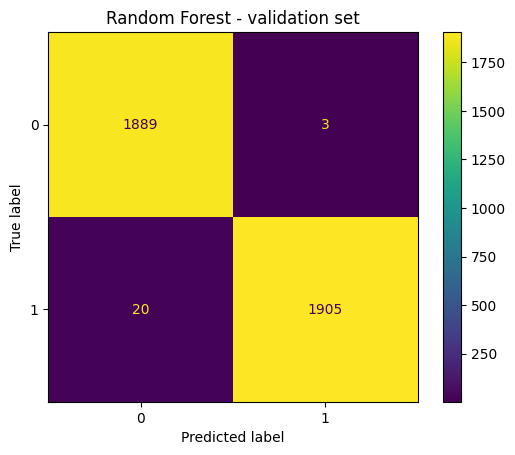

In [38]:
# Create a confusion matrix to visualize the results of the classification model

# Compute values for confusion matrix
log_cm = confusion_matrix(y_val, y_preds)

# Create display of confusion matrix using ConfusionMatrixDisplay()
log_disp = ConfusionMatrixDisplay(confusion_matrix=log_cm, display_labels=None)

# Plot confusion matrix
log_disp.plot()
plt.title('Random Forest - validation set');

# Display plot
plt.show()


Create a classification report that includes precision, recall, f1-score, and accuracy metrics to evaluate the performance of the model.
<br> </br>

**Note:** In other labs there was a custom-written function to extract the accuracy, precision, recall, and F<sub>1</sub> scores from the GridSearchCV report and display them in a table. You can also use scikit-learn's built-in [`classification_report()`](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-report) function to obtain a similar table of results.

In [39]:
# Create a classification report
# Create classification report for random forest model
target = ['opinion', 'claim']

print(classification_report(y_val, y_preds, target_names=target))

              precision    recall  f1-score   support

     opinion       0.99      1.00      0.99      1892
       claim       1.00      0.99      0.99      1925

    accuracy                           0.99      3817
   macro avg       0.99      0.99      0.99      3817
weighted avg       0.99      0.99      0.99      3817



**Question:** What does your classification report show? What does the confusion matrix indicate?

**Response:** O relatório de classificação mostra que o modelo Random Forest apresentou excelente desempenho. A matriz de confusão indica que houve apenas 27 classificações incorretas no conjunto de validação. Foram 7 falsos positivos (observações da classe opinion classificadas como claim) e 20 falsos negativos (observações da classe claim classificadas como opinion). Isso demonstra que o modelo classificou corretamente a grande maioria das observações e possui alta capacidade de distinção entre as duas classes.

#### **XGBoost**

Now, evaluate the XGBoost model on the validation set.

In [40]:
# Use the best estimator to predict on the validation data
y_preds = xgb_cv.best_estimator_.predict(X_val_final)


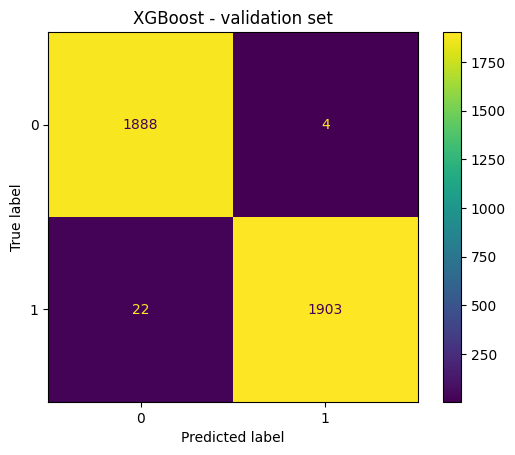

In [41]:
# Compute values for confusion matrix
log_cm = confusion_matrix(y_val, y_preds)

# Create display of confusion matrix using ConfusionMatrixDisplay()
log_disp = ConfusionMatrixDisplay(confusion_matrix=log_cm, display_labels=None)

# Plot confusion matrix
log_disp.plot()
plt.title('XGBoost - validation set');

# Display plot
plt.show()


In [42]:
# Create a classification report
target = ['opinion', 'claim']

print(classification_report(y_val, y_preds, target_names=target))


              precision    recall  f1-score   support

     opinion       0.99      1.00      0.99      1892
       claim       1.00      0.99      0.99      1925

    accuracy                           0.99      3817
   macro avg       0.99      0.99      0.99      3817
weighted avg       0.99      0.99      0.99      3817



**Question:** Describe your XGBoost model results. How does your XGBoost model compare to your random forest model?

**Response:** modelo XGBoost também apresentou desempenho excelente, Em comparação com o Random Forest, o desempenho foi praticamente o mesmo. Embora as métricas obtidas durante a validação tenham indicado uma ligeira vantagem para o Random Forest, a diferença é mínima.

### **Use champion model to predict on test data**

In [43]:
### YOUR CODE HERE ###
y_pred = rf_cv.best_estimator_.predict(X_test_final)

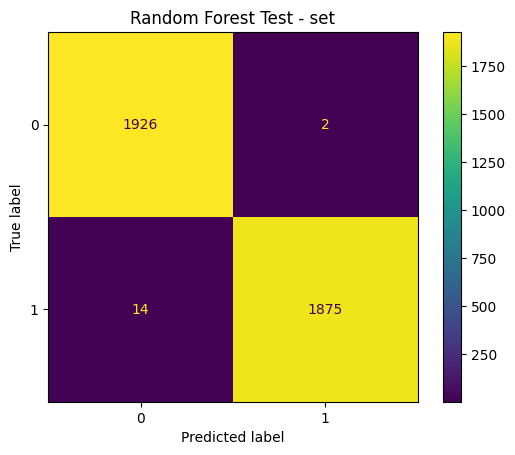

In [44]:
# Compute values for confusion matrix
log_cm = confusion_matrix(y_test, y_pred)

# Create display of confusion matrix using ConfusionMatrixDisplay()
log_disp = ConfusionMatrixDisplay(confusion_matrix=log_cm, display_labels=None)

# Plot confusion matrix
log_disp.plot()
plt.title('Random Forest Test - set')
# Display plot
plt.show()


#### **Feature importances of champion model**


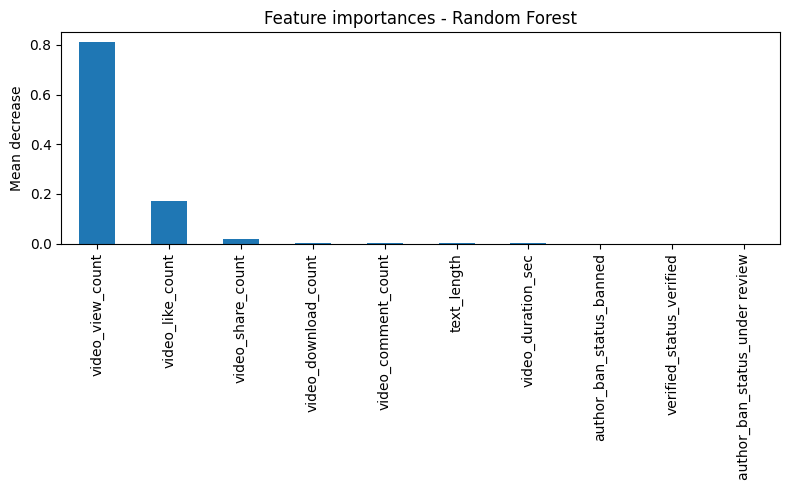

In [45]:
importances = rf_cv.best_estimator_.feature_importances_

rf_importances = pd.Series(
    importances,
    index=X_test_final.columns
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8,5))
rf_importances.plot.bar(ax=ax)

ax.set_title('Feature importances - Random Forest')
ax.set_ylabel('Mean decrease')

fig.tight_layout()
plt.show()

**Question:** Describe your most predictive features. Were your results surprising?

**Response:** As características mais preditivas estavam relacionadas principalmente aos níveis de engajamento gerados pelos vídeos, especialmente video_view_count, video_like_count, video_share_count e video_download_count. Esses resultados não foram surpreendentes, pois a análise exploratória dos dados (EDA) já indicava que as métricas de engajamento teriam forte influência na classificação dos vídeos.

### **Task 8. Conclusion**

In this step use the results of the models above to formulate a conclusion. Consider the following questions:

1. **Would you recommend using this model? Why or why not?**

2. **What was your model doing? Can you explain how it was making predictions?**

3. **Are there new features that you can engineer that might improve model performance?**

4. **What features would you want to have that would likely improve the performance of your model?**

Remember, sometimes your data simply will not be predictive of your chosen target. This is common. Machine learning is a powerful tool, but it is not magic. If your data does not contain predictive signal, even the most complex algorithm will not be able to deliver consistent and accurate predictions. Do not be afraid to draw this conclusion.


**Response:** Os modelos Random Forest e XGBoost apresentaram excelente desempenho, com precisão, recall e acurácia próximas de 99%. Entre eles, o Random Forest obteve resultados ligeiramente melhores e foi selecionado como modelo final. As variáveis mais importantes estavam relacionadas ao engajamento dos vídeos, especialmente visualizações, curtidas e compartilhamentos. Com base nos resultados obtidos, o modelo é recomendado para essa tarefa, pois demonstrou alta capacidade de distinguir corretamente conteúdos do tipo claim e opinion.

**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged.